# GPAW + WannierBerri: Altermagnet MnTe

It is assumed that the reader is familiar with the previous tutorial on bcc Fe with GPAW. In this tutorial we will show a special case, the crystal structure is anti-ferromagnetic.
MnTe has two Mn atoms per unit cell with opposite directions of magnetic moments. As a result in spin-up states, the Mn1 d-states are occupied, while the Mn2 d-states are empty. In the spin-down channel the situation is reversed. Thus, to wannierise only the valence bands, one may want to introduce different projections for the two spin channels.

In [1]:
import numpy as np
from ase import Atoms
from gpaw import GPAW, PW, MixerSum

from wannierberri.logging import configure_logging
import logging
configure_logging(console_level=logging.INFO)

import ray
ray.init(num_cpus=16)

seed = "MnTe"

a = 4.134
c = 6.652
lattice = a * np.array([[1, 0, 0], [-1 / 2, np.sqrt(3) / 2, 0], [0, 0, c / a]])
positions = np.array(
    [
        [0, 0, 0],
        [0, 0, 1 / 2],
        [1 / 3, 2 / 3, 1 / 4],
        [2 / 3, 1 / 3, 3 / 4],
    ]
)

/home/stepan/miniconda3/envs/wbdev314/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-12 02:34:25,306	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-11-12 02:34:25,331	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html
2026-11-12 02:34:27,476	INFO worker.py:2038 -- Started a local Ray instance.



## Step 1: Gpaw calculation

### loading the GPAW calculators

If you want to skip the GPAW calculation, you can just load the pre-calculated calculators (not included in the repository due to size, but if you have run gpaw once, you can find them in the `gpaw` folder). 



In [2]:
calc_scf = GPAW(f"gpaw/{seed}-scf.gpw")
calc_nscf = GPAW(f"gpaw/{seed}-nscf-irred-664.gpw")
calc_bands = GPAW(f"gpaw/{seed}-bands-path.gpw")


### self-consistent calculation

In [ ]:
a = 4.134
c = 6.652
lattice = a * np.array([[1, 0, 0], [-1 / 2, np.sqrt(3) / 2, 0], [0, 0, c / a]])
positions = np.array(
    [
        [0, 0, 0],
        [0, 0, 1 / 2],
        [1 / 3, 2 / 3, 1 / 4],
        [2 / 3, 1 / 3, 3 / 4],
    ]
)
atoms = Atoms("Mn2Te2",
                cell=lattice,
                scaled_positions=positions,
                pbc=[1, 1, 1])

m = 4.7
magmoms = np.zeros(4)
magmoms[0] = +m
magmoms[1] = -m
atoms.set_initial_magnetic_moments(magmoms)

calc = GPAW(
    mode=PW(600),
    xc="PBE",
    kpts={"size": [6, 6, 4], "gamma": True},
    convergence={"density": 1e-6},
    mixer=MixerSum(0.25, 8, 100),
    setups={"Mn": ":d,4.0"},
    txt="rpaw/MnTe_scf.txt"
)
atoms.calc = calc
atoms.get_potential_energy()
calc.write(f"gpaw/{seed}-scf.gpw", mode="all")


### Non-self-consistent calculation in the irreducible Brillouin zone

Now we get the list of irreducible k-points (using irrep.SpaceGroup object) and perform a non-self-consistent calculation only on these k-points. 
Note, that here we use all symmetries of the crystal structure, even those which are broken by the magnetization direction, because they are still symmetries for each spin channel separately (including the time-reversal symmetry).

In [ ]:
from irrep.spacegroup import SpaceGroup
sg = SpaceGroup.from_gpaw(calc)
kpoints_irred = sg.get_irreducible_kpoints_grid([6, 6, 4])
calc_nscf = calc.fixed_density(
    kpts=kpoints_irred,
    symmetry={'symmorphic': False},
    nbands=60,
    convergence={'bands': 40},
    txt=f'gpaw/{seed}-nscf.txt')
calc_nscf.write(f'gpaw/{seed}-nscf-irred-664.gpw', mode='all')

### Compute the dft bandstructure along a high-symmetry path

This is done to compare with the wannierized bandstructure later.

In [ ]:
from wannierberri.grid import Path
# recip_lattice = 2*np.pi * np.linalg.inv(lattice).T
kz = 0.35 / (2*np.pi/c)
path = Path(lattice,
            nodes=[
                [2 / 3, -1 / 3, 0],
                [0, 0, 0],
                [-2 / 3, 1 / 3, 0],
                None,
                [-0.5, 0, kz],
                [0, 0, kz],
                [0.5, 0, kz],
            ],
            labels=[r"${\rm K}\leftarrow$",
                    r"$\Gamma$",
                    r"$\rightarrow{\rm K}$",
                    r"$\overline{\rm M}\leftarrow$",
                    r"$\overline{\Gamma}$",
                    r"$\rightarrow\overline{\rm M}$"],
            length=100)   # length [ Ang] ~= 2*pi/dk
kpoints = path.K_list
print (kpoints.shape)
print (kpoints)

calc_bands = calc_scf.fixed_density(
    nbands=30,
    symmetry='off',
    random=True,
    kpts=kpoints,
    txt=f'gpaw/{seed}-bands-path.txt',
    convergence={'bands': 24})
calc_bands.write(f'gpaw/{seed}-bands-path.gpw', mode='all')


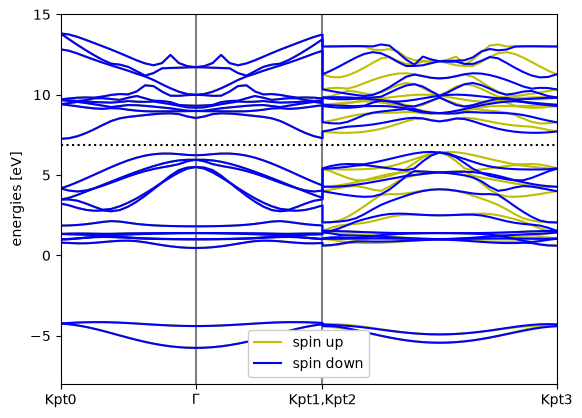

<Axes: ylabel='energies [eV]'>

In [3]:
bs_dft = calc_bands.band_structure()
bs_dft.plot(show=True, emin=-8,emax=15.0)

## Step 2: Wannierization

#### 2.1 select projections

In this case we use sp2 and pz projections on Te atoms, because that suits their point group.  
To wannierise the spin-up channel we use only the Mn1 d-states, the Mn2 d-states not occupied. 
We do NOT explicitly wannierise the spin-down channel, because it is related to the spin-up channel by some symmetry, which will be detected automatically. 

In [4]:
from irrep.spacegroup import SpaceGroup
from wannierberri.symmetry.projections import Projection, ProjectionsSet

sg = SpaceGroup.from_gpaw(calc_nscf)

positions_Mn = [[0, 0, 0],
                [0, 0, 1 / 2]]

positions_Te = [[1 / 3, 2 / 3, 1 / 4],
                [2 / 3, 1 / 3, 3 / 4]]

proj_Mn1_d = Projection(position_num=positions_Mn[0], orbital='d', spacegroup=sg)

proj_Te_sp2 = Projection(position_num=positions_Te, orbital='sp2', spacegroup=sg, xaxis=[0, -1, 0], rotate_basis=True)
proj_Te_pz = Projection(position_num=positions_Te, orbital='pz', spacegroup=sg)

proj_set_up = ProjectionsSet([proj_Mn1_d, proj_Te_sp2, proj_Te_pz])



### create the "w90 files"

Here we are NOT using the gpaw-wannier90 interface, and actually not creating the w90 files, but directly access the wavefunctions from the GPAW calculation, use symmetry operations from irrep, and create the necessary data to be used with wannierberri. Those files still retain the same naming convention as the w90 files for consistency, but htey are binary npz files, which are convenient to work with numpy


After creating those data, it is written to the disk, so that one can later load it. But be careful - if you change anything (e.g. the projections)  - do not forget to remove those files, otherwise you will load the old data! For that reason, here we set 'read_npz_list=[]' to force the creation of new data.

In [6]:
from wannierberri.w90files.wandata_soc import WannierDataSOC
wandata = WannierDataSOC.from_gpaw(
    seedname="wannier_soc",
    calculator=calc_nscf,
    projections_up=proj_set_up,
    mp_grid=(6, 6, 4),
    spacegroup=sg,
    files=["soc", "mmn", "amn", "eig", "symmetrizer"],
    altermagnetic=True,
    irreducible=True
)
wandata.to_npz("wannier_soc_altermagnetic")

2026-11-12 02:36:02,434 INFO wannierberri.w90files.amn: Creating amn. Using projections_set 
ProjectionsSet with 13 Wannier functions and 0 free variables
Projection 0.0, 0.0, 0.0:['d'] with 5 Wannier functions (5 per spin x1 spins) 
 on 1 points (5 per site)
Projection 0.3333333333333333, 0.6666666666666666, 0.25:['sp2'] with 6 Wannier functions (6 per spin x1 spins) 
 on 2 points (3 per site)
Projection 0.3333333333333333, 0.6666666666666666, 0.25:['pz'] with 2 Wannier functions (2 per spin x1 spins) 
 on 2 points (1 per site)
2026-11-12 02:36:02,728 INFO wannierberri.w90files.mmn: NK= 144, selected_kpoints = [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23], kptirr = [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
2026-11-12 02:36:02,730 INFO wannierberri.w90files.mmn: Using PAW kpoints for MMN: [array([0., 0., 0.]), array([0.  , 0.  , 0.25]), array([0. , 0. , 0.5]), array([0.        , 0.16666667, 0.        ]), array([0.        , 0.1

### Do the wannierization

at this step we also specify the frozen window, number of iterations, and whether to use site 
symmetry and localization. (when starting from irreducible BZ, site-symmetry is required anyway)

We also may use the outer window via w90data.select_bands if needed

In this case, both spin channels will be wannierised separately, starting from the same projections.There is also an option to specify different projections for different spin channels if needed. (See MnTe tutorial)

In [7]:
wandata.wannierise(
    froz_min=-10,
    froz_max=7,
    outer_min=-10,
    outer_max=np.inf,
    num_iter=100,
    print_progress_every=50,
    sitesym=True,
    localise=True,
    check_sym_accuracy=1e-5,
    check_sym_no_exclude_bands=-10,
)



2026-11-12 02:36:08,626 WARNING wannierberri.wannierisation.wannierise: The check of irreps is not implemented for anti-unitary symmetries. Skipping the check, leaving to your responsibility
2026-11-12 02:36:08,627 INFO wannierberri.wannierisation.wannierise: Using the Wannier centers from the projections as initial guess
2026-11-12 02:36:08,775 WARNING wannierberri.symmetry.sawf_kirr: symmetrization+orthogonalization did not converge in 10 iterations, final changes 0.005028621920674698, 3.970459310517417e-05; probably the input data are not perfectly symmetrizable, or the provided projections are notcompatible with the irreps of the DFT bands.
2026-11-12 02:36:08,931 WARNING wannierberri.symmetry.sawf_kirr: symmetrization+orthogonalization did not converge in 10 iterations, final changes 0.003620773930459292, 2.0823989316852954e-05; probably the input data are not perfectly symmetrizable, or the provided projections are notcompatible with the irreps of the DFT bands.
2026-11-12 02:36:

### Create the System object to be used in WannierBerri calculations

It is called "System_w90" class, although it now does not use the w90 wannierization, but the class is the same.

Unlike the non-SOC systems, here we also specify the direction of the magnetization. We can later easily chanbge this direction without redoing the wannierization.

In [10]:
from wannierberri.system.system_soc import SystemSOC

system_soc = SystemSOC.from_wannierdata(wandata=wandata, berry=True, silent=False)
system_soc.to_npz("system_soc_altermagnetic")


2026-11-12 02:38:20,564 INFO wannierberri.system.system_w90: irreducible : True, symmetrize set to True
2026-11-12 02:38:20,742 INFO wannierberri.symmetry.sym_wann_2: num_blocks_left = 3, num_blocks_right = 3
2026-11-12 02:38:20,742 INFO wannierberri.system.system_R: number o R-vectors before symmetrization: 267
2026-11-12 02:38:21,019 INFO wannierberri.system.system_R: number o R-vectors after symmetrization: 573
2026-11-12 02:38:21,182 INFO wannierberri.symmetry.sym_wann_2: num_blocks_left = 3, num_blocks_right = 3
2026-11-12 02:38:21,456 INFO wannierberri.system.system_soc: using magmoms 
 [[ 0.00000000e+00  0.00000000e+00  4.40436811e+00]
 [-0.00000000e+00 -0.00000000e+00 -4.40436811e+00]
 [-0.00000000e+00 -0.00000000e+00 -2.92436898e-10]
 [-0.00000000e+00 -0.00000000e+00 -2.92436898e-10]]
2026-11-12 02:38:21,476 INFO wannierberri.system.system_soc: Saving SystemSOC to system_soc_altermagnetic
2026-11-12 02:38:21,477 INFO wannierberri.system.system_R: saving system of class SystemS

### Compute the wannierized bandstructure with SOC along the high-symmetry path

In [11]:
from wannierberri.grid import Path
from wannierberri.evaluate_k import evaluate_k_path
from wannierberri.system.system_soc import SystemSOC

system_soc = SystemSOC.from_npz("system_soc_altermagnetic")
theta = 90
phi = 90
system_soc.set_soc_axis(theta=theta, phi=phi, alpha_soc=1.0, units="degrees")
kz = 0.35 / (2*np.pi/c)
path = Path.from_nodes(real_lattice=lattice,
            nodes=[
                [2 / 3, -1 / 3, 0],
                [0, 0, 0],
                [-2 / 3, 1 / 3, 0],
                None,
                [-0.5, 0, kz],
                [0, 0, kz],
                [0.5, 0, kz],
            ],
            labels=[r"${\rm K}\leftarrow$",
                    r"$\Gamma$",
                    r"$\rightarrow{\rm K}$",
                    r"$\overline{\rm M}\leftarrow$",
                    r"$\overline{\Gamma}$",
                    r"$\rightarrow\overline{\rm M}$"],
            length=300)   # length [ Ang] ~= 2*pi/dk

bands_wannier_soc= evaluate_k_path(system_soc, path=path, quantities=["spin"])
bands_wannier_up = evaluate_k_path(system_soc.system_up, path=path)
bands_wannier_dw = evaluate_k_path(system_soc.system_down, path=path)
                                

2026-11-12 02:38:28,543 INFO wannierberri.system.system_soc: using magmoms 
 [[ 2.69689765e-16  4.40436811e+00  2.69689765e-16]
 [-2.69689765e-16 -4.40436811e+00 -2.69689765e-16]
 [-1.79065955e-26 -2.92436898e-10 -1.79065955e-26]
 [-1.79065955e-26 -2.92436898e-10 -1.79065955e-26]]
2026-11-12 02:38:28,548 OUTPUT wannierberri.run_grid: 
 Using the follwing calculators :
############################################################

 'tabulate'  :  <wannierberri.calculators.tabulate.TabulatorAll object at 0x7c102c01bd90>  : 
TabulatorAll - a pack of all k-resolved calculators (Tabulators)

 Includes the following tabulators : 
--------------------------------------------------
 "spin" : <wannierberri.calculators.tabulate.Spin object at 0x7c12d299f770> : Spin expectation :math:` \langle u | \mathbf{\sigma} | u \rangle`

 "Energy" : <wannierberri.calculators.tabulate.Energy object at 0x7c12a8473b10> : calculator not described

--------------------------------------------------

2026-11-12 02

## Plot the Bandstructure with and without SOC

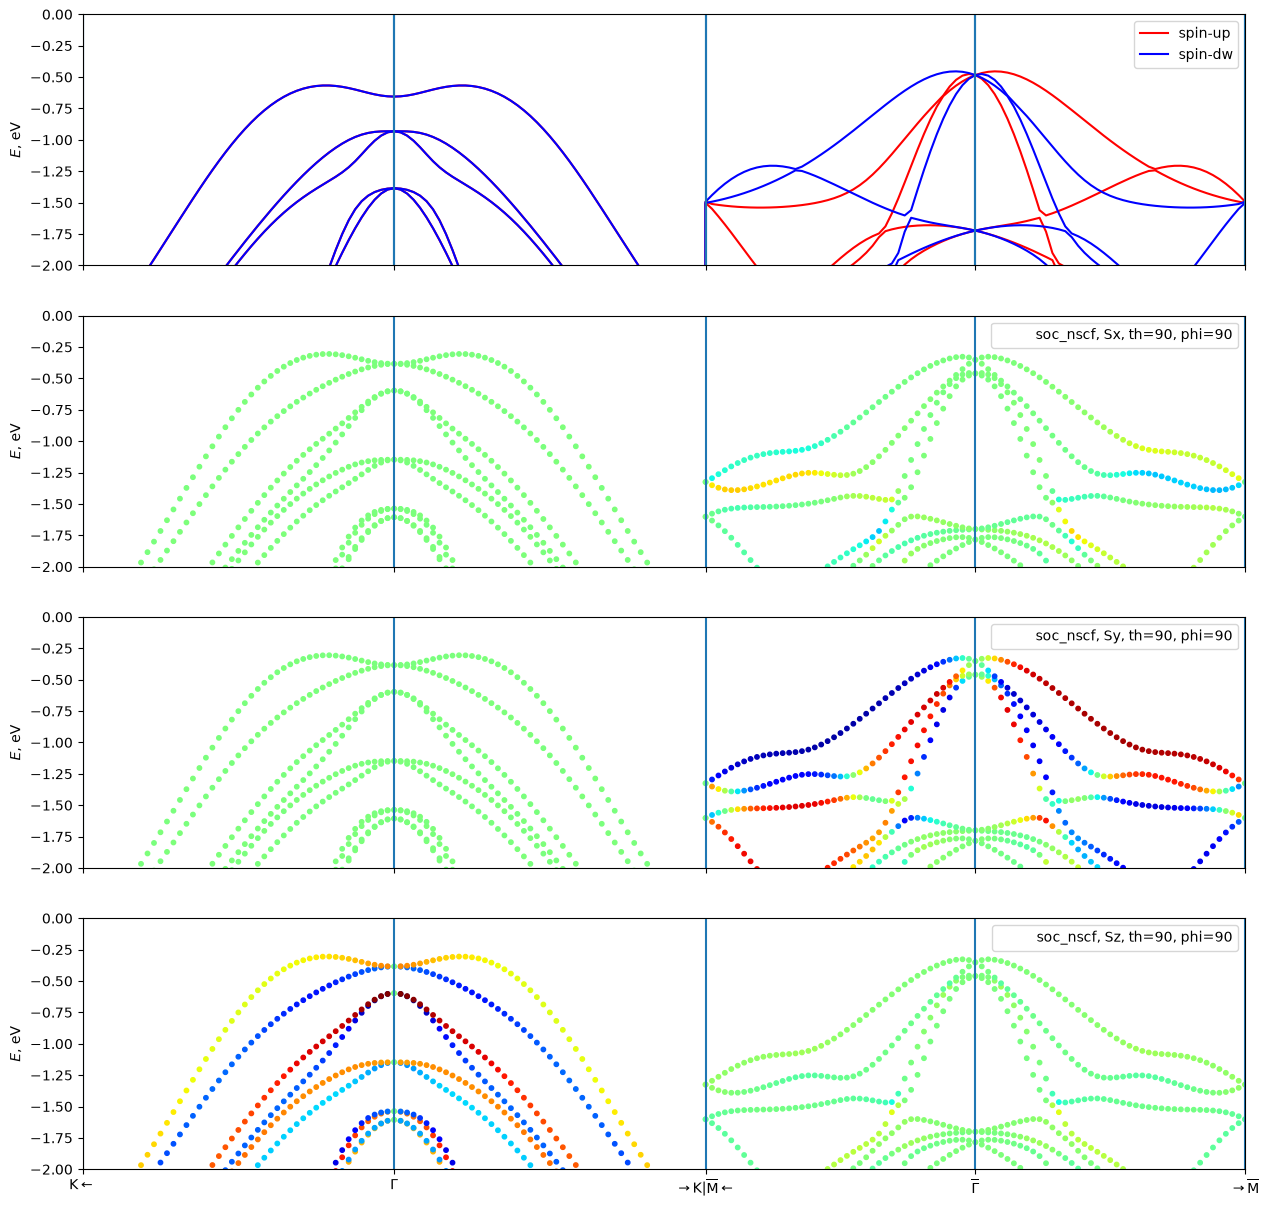

In [12]:
from matplotlib import pyplot as plt

EF = 6.885145845031927

fig, axes = plt.subplots(4, 1, sharey=True, sharex=True, figsize=(15, 15))

for i in range(3):
    component = "xyz"[i]
    bands_wannier_soc.plot_path_fat(path=path,
                       Eshift=EF,
                       quantity="spin",
                       component=component,
                       mode="color",
                       label=f"soc_nscf, S{component}, th={theta}, phi={phi}",
                        axes=axes[1 + i],
                       fatmax=10,
                        linecolor="orange",
                        close_fig=False,
                        show_fig=False,
                        kwargs_line=dict(linestyle='-', lw=0.0),
    )


bands_wannier_up.plot_path_fat(path=path,
                       Eshift=EF,
                       axes=axes[0],
                       label="spin-up",
                       linecolor="red",
                       close_fig=False,
                       show_fig=False,
)

bands_wannier_dw.plot_path_fat(path=path,
                       label="spin-dw",
                       axes=axes[0],
                       Eshift=EF,
                       linecolor="blue",
                       close_fig=False,
                       show_fig=False,)

plt.ylim(-2,0)
plt.show()


## AHC

### magnetic moments along "y" direction

Below we evaluate only the "internal" (which depend only on the Hamiltonian) contributions to the anomalous Hall conductivity (AHC), how to include the "external" contributions is explained in the previous tutorial on bcc Fe.

In [13]:
import os
import numpy as np
import wannierberri as wb
from wannierberri.system.system_soc import SystemSOC

system_soc_y = SystemSOC.from_npz("system_soc_altermagnetic")
theta=90
phi=90
system_soc_y.set_soc_axis(theta=theta, phi=phi, units="degrees")

grid = wb.grid.Grid(system_soc_y, NK=200)

EF = 6.885145845031927
tetra = False

Efermi = np.linspace(EF - 2, EF, 1001)

os.makedirs("results", exist_ok=True)
result_int = wb.run(system_soc_y,
        grid=grid,
        fout_name=f"results/{seed}-soc-y",
        calculators={"ahc_int": wb.calculators.static.AHC(Efermi=Efermi, tetra=tetra, kwargs_formula={"external_terms": False})},
        adpt_num_iter=20,
        )


2026-11-12 02:39:55,573 INFO wannierberri.system.system_soc: using magmoms 
 [[ 2.69689765e-16  4.40436811e+00  2.69689765e-16]
 [-2.69689765e-16 -4.40436811e+00 -2.69689765e-16]
 [-1.79065955e-26 -2.92436898e-10 -1.79065955e-26]
 [-1.79065955e-26 -2.92436898e-10 -1.79065955e-26]]
2026-11-12 02:39:56,051 INFO wannierberri.grid.grid: Minimal symmetric FFT grid : [13 13  8]
2026-11-12 02:39:56,117 INFO wannierberri.grid.grid: The grids were set to NKdiv=[10 10 25], NKFFT=[20 20  8], NKtot=[200 200 200]
2026-11-12 02:39:56,118 OUTPUT wannierberri.run_grid: 
 Using the follwing calculators :
############################################################

 'ahc_int'  :  <wannierberri.calculators.static.AHC object at 0x7c1000606660>  : Anomalous Hall conductivity (:math:`s^3 \cdot A^2 / (kg \cdot m^3) = S/m`)

| With Fermi sea integral Eq(11) in `Ref <https://www.nature.com/articles/s41524-021-00498-5>`__
| Output: :math:`O = -e^2/\hbar \int [dk] \Omega f`
| Instruction: :math:`j_\alpha = \sig

### plot AHC vs energy

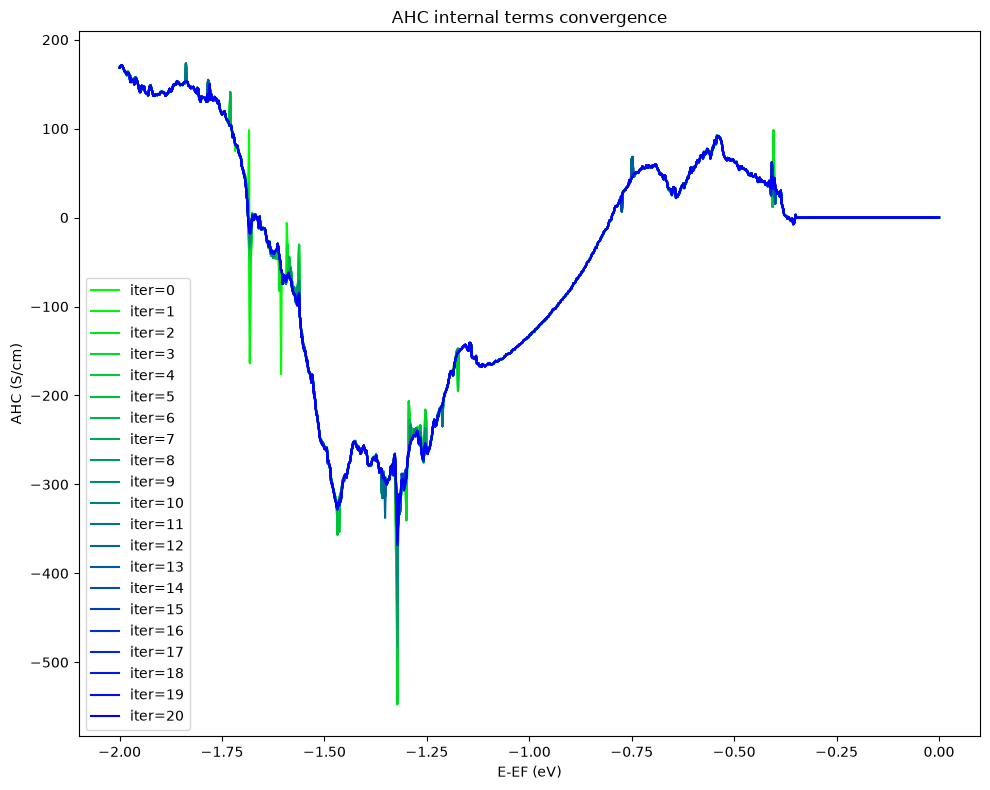

In [14]:
from matplotlib import pyplot as plt
import numpy as np
theta=0
phi=0


fig, axes = plt.subplots(1, 1, sharey=False, sharex=True, figsize=(10, 8))
axes=[axes]
imin = 0
imax = 20
for i in range(imin, imax+1, 1):
    t = (i-imin)/(imax-imin)
    res =  np.load(f"results/MnTe-soc-y-ahc_int_iter-{i:04d}.npz")
    Efermi = res['Energies_0']
    ahc = res["data"]
    axes[0].plot(Efermi - EF, ahc[:,2]/100, label=f"iter={i}", color=(0, 1-t, t))
axes[0].set_title("AHC internal terms convergence")
# axes[0].set_ylim(-1000, 0)
axes[0].set_xlabel("E-EF (eV)")
axes[0].set_ylabel("AHC (S/cm)")
axes[0].legend()
plt.tight_layout()
plt.savefig("ahc_convergence.png", dpi=300)

We can observe 3 things, which are generally true, not only for AHC, but for most other effects:
1. The internal terms converge slower than the external ones.
2. The external terms usually give a smaller contribution. Often (but not always) it is negligible. However, check it for a particular material and effect.
3. The external terms take more time to evaluate per k-point. 

Thus, it makes sense to evaluate them separately, using different k-point grids and number of iterations for the adaptive integration.

## Other directions of magnetic moments

We could try to calculate the AHC when the magnetic moments are along "z" or "x" directions. However, we can see that in those cases the point group contains symmetries which force the AHC to be zero. 
This can be demonstrated by the following way:

In [15]:
from irrep.spacegroup import SpaceGroup
from wannierberri.symmetry.point_symmetry import PointGroup

#  x direction
mg = SpaceGroup.from_cell(real_lattice=lattice, positions=positions, typat=[1,1,2,2], magmom=[[1,0,0],[-1,0,0],[0,0,0],[0,0,0]])
# mg.show()
pointgroup = PointGroup(spacegroup=mg)
print (f"components of AHC for magnetic moments along x direction: {pointgroup.get_symmetric_components(rank=1, TRodd=True, Iodd=False)}")

mg = SpaceGroup.from_cell(real_lattice=lattice, positions=positions, typat=[1,1,2,2], magmom=[[0,1,0],[0,-1,0],[0,0,0],[0,0,0]])
# mg.show()
pointgroup = PointGroup(spacegroup=mg)
print (f"components of AHC for magnetic moments along y direction: {pointgroup.get_symmetric_components(rank=1, TRodd=True, Iodd=False)}")

mg = SpaceGroup.from_cell(real_lattice=lattice, positions=positions, typat=[1,1,2,2], magmom=[[0,0,1],[0,0,-1],[0,0,0],[0,0,0]])
# mg.show()
pointgroup = PointGroup(spacegroup=mg)
print (f"components of AHC for magnetic moments along z direction: {pointgroup.get_symmetric_components(rank=1, TRodd=True, Iodd=False)}")

components of AHC for magnetic moments along x direction: ['0=x=y=z']
components of AHC for magnetic moments along y direction: ['0=x=y', 'z']
components of AHC for magnetic moments along z direction: ['0=x=y=z']
